# Phase 4f: Georgia solar learning curve

**Date:** 2026-11-04  
**Driver:** `code/python/04f_georgia_solar.py --date 2026-11-04`  
**Results:** `results/2026-11-04/georgia_solar/`

**What this is:** arithmetic on what utility-scale solar could cost in Georgia by 2035 if costs follow a learning curve. **There's no AI variable here, and it says nothing about whether AI affects renewables. None of these numbers is a forecast of ours.**

In [1]:
import pandas as pd
from IPython.display import display, Image
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 60)
R = '../results/2026-11-04/georgia_solar/'

## What a learning curve is

A learning curve says cost falls by a fixed percentage each time cumulative deployment doubles. With a 24% learning rate, doubling global capacity cuts cost by 24%, and doubling again cuts it another 24%, to 58% of the start. The formula is C(t) = C(base) x (X(t) / X(base))^b, with b = ln(1 - LR) / ln 2. At 24%, b is about -0.396.

Learning curves are correlations: "the direction of causality is not clear" (Bolinger et al. 2022). Deployment can lower costs, and lower costs can raise deployment.

In [2]:
print('24% learning rate, per doubling:', [round(100 * 0.76 ** k, 1) for k in range(4)])

24% learning rate, per doubling: [100.0, 76.0, 57.8, 43.9]


## Base cost

Capacity-weighted LCOE without tax credits, for projects in service in 2023-2025 (LBNL). We don't use PPA prices, because they include tax credits. Georgia has no learning rate of its own, so we apply global rates, which holds Georgia's proportional gap to the U.S. constant. That's our assumption.

In [3]:
display(pd.read_csv(R + 'base_cost.csv').drop(columns='source'))

,area,window,n_projects,mw_ac,lcoe_capacity_weighted,lcoe_median,lcoe_p25,lcoe_p75,x_base_gw
0,Georgia,COD 2023-2025,17,1750.0,63.81,67.85,52.04,81.91,1936.3
1,Southeast (non-ISO),COD 2023-2025,131,9926.1,58.69,54.86,50.29,62.17,1844.0
2,United States,COD 2023-2025,592,66133.5,58.64,61.19,51.26,76.76,1918.9


## Capacity paths

From IEA's *World Energy Outlook 2025*, Annex A: Current Policies (Table A.3a, p. 417), Stated Policies (A.3b, p. 423) and Net Zero Emissions by 2050 (A.3c, p. 429). IEA's capacity base differs from IRENA's, so we apply IEA's 2024-2035 growth ratio to IRENA's series. Years between 2025 and 2035 are our interpolation. Net Zero is a normative scenario, not a projection.

In [4]:
p = pd.read_csv(R + 'capacity_paths.csv'); display(p[p.year.isin([2025, 2030, 2035])][['path', 'source', 'source_location', 'iea_2035_gw', 'growth_ratio_2024_2035', 'year', 'global_pv_gw']])

,path,source,source_location,iea_2035_gw,growth_ratio_2024_2035,year,global_pv_gw
0,Low,IEA WEO 2025 Current Policies,"Table A.3a, p. 417",8067,3.7278,2025,2378.0
5,Low,IEA WEO 2025 Current Policies,"Table A.3a, p. 417",8067,3.7278,2030,4068.2
10,Low,IEA WEO 2025 Current Policies,"Table A.3a, p. 417",8067,3.7278,2035,6959.5
11,Central,IEA WEO 2025 Stated Policies,"Table A.3b, p. 423",8855,4.0920,2025,2378.0
16,Central,IEA WEO 2025 Stated Policies,"Table A.3b, p. 423",8855,4.0920,2030,4262.2
21,Central,IEA WEO 2025 Stated Policies,"Table A.3b, p. 423",8855,4.0920,2035,7639.3
22,High,IEA WEO 2025 Net Zero Emissions by 2050,"Table A.3c, p. 429",12499,5.7759,2025,2378.0
27,High,IEA WEO 2025 Net Zero Emissions by 2050,"Table A.3c, p. 429",12499,5.7759,2030,5063.8
32,High,IEA WEO 2025 Net Zero Emissions by 2050,"Table A.3c, p. 429",12499,5.7759,2035,10783.0


## The fan

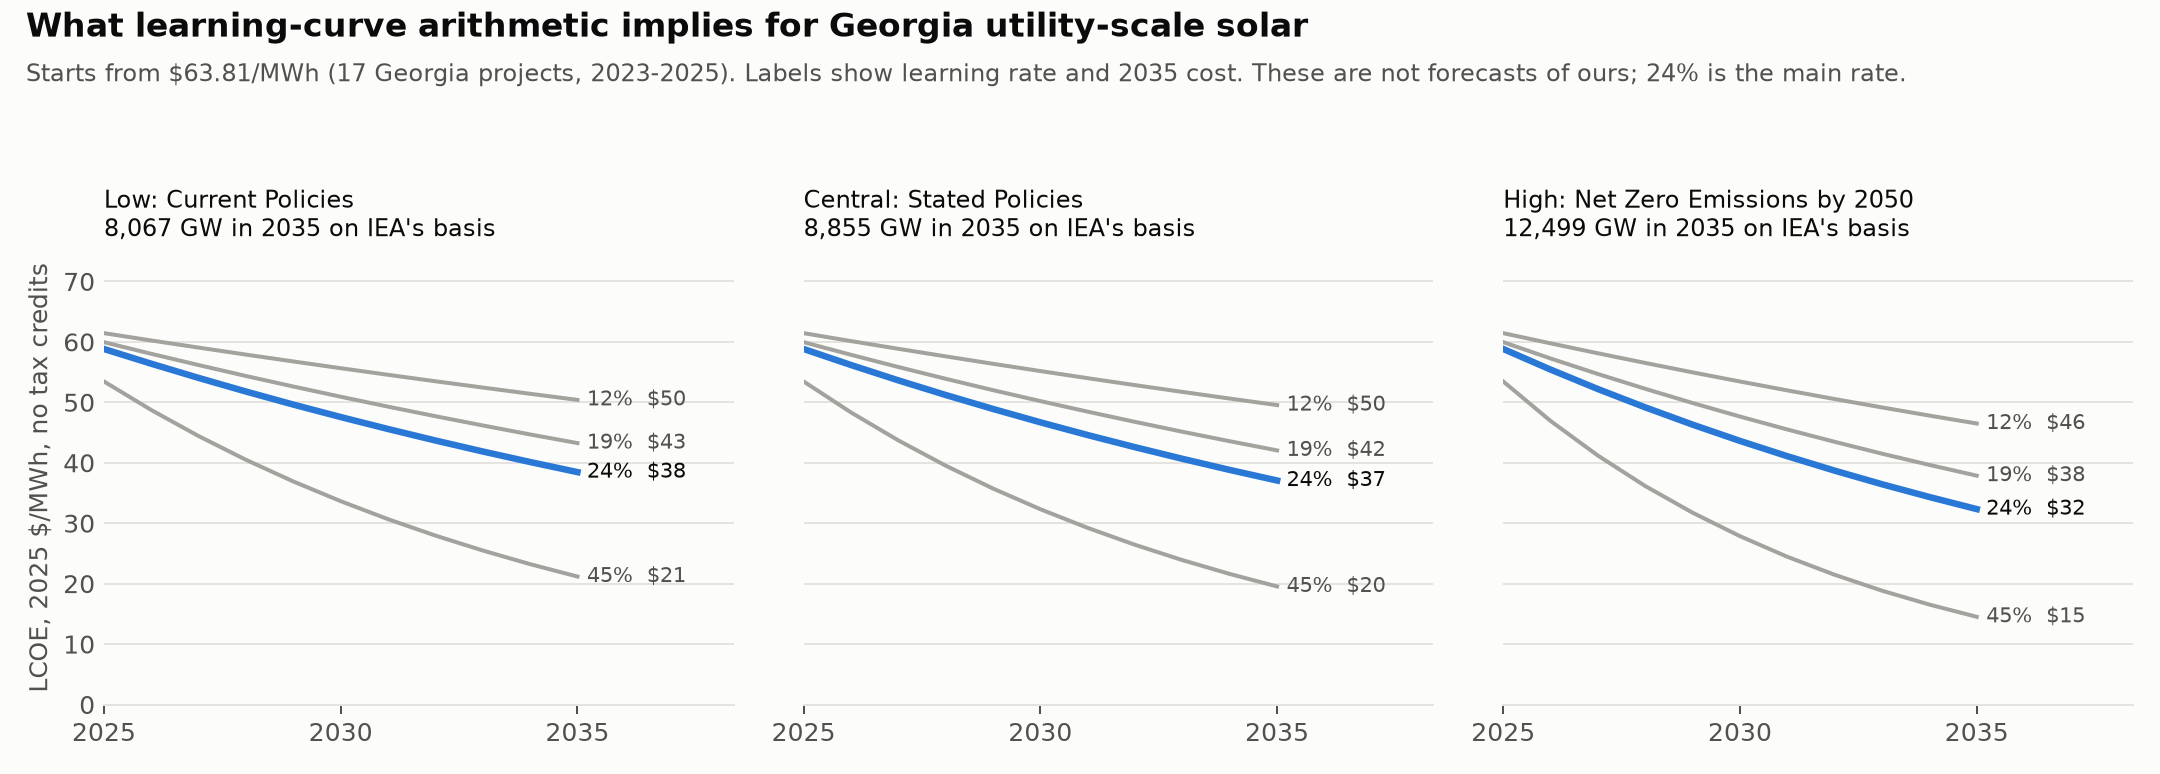

,lr_label,path,2025,2030,2035,change_2025_2035_pct
0,12%,Low,61.44,55.64,50.40,-18.0
1,12%,Central,61.44,55.17,49.54,-19.4
2,12%,High,61.44,53.44,46.49,-24.3
3,19% (CapEx),Low,59.95,50.92,43.25,-27.9
4,19% (CapEx),Central,59.95,50.20,42.04,-29.9
5,19% (CapEx),High,59.95,47.64,37.86,-36.8
6,24% (main),Low,58.82,47.56,38.45,-34.6
7,24% (main),Central,58.82,46.69,37.06,-37.0
8,24% (main),High,58.82,43.61,32.33,-45.0
9,45% (2014-2020 epoch),Low,53.45,33.64,21.17,-60.4


In [5]:
display(Image('../results/2026-11-04/figures/04f_georgia_fan.png', width=950))
display(pd.read_csv(R + 'projection_table.csv'))

## Learning-rate check

Bolinger's equation 2 on LBNL's published national series. Our 29.0% for 2010-2024 compares with the paper's 27% on raw data and 24% normalized.

**The main caution:** LCOE rose from $49.0 in 2022 to $61.0 in 2025 while global capacity more than doubled. The curve assumes costs resume falling with deployment. Recent years don't show that yet.

In [6]:
display(pd.read_csv(R + 'learning_rate_check.csv').drop(columns='note')); display(pd.read_csv(R + 'national_lcoe_lbnl_tab.csv'))

,series,window,n_years,b,se_b,learning_rate_pct,r2
0,LBNL tab,2010-2024,15,-0.4938,0.0352,29.0,0.938
1,LBNL tab,2010-2021,12,-0.5711,0.0278,32.7,0.977
2,LBNL tab,2010-2025,16,-0.4492,0.0409,26.8,0.896
3,Rebuilt from projects,2013-2024,12,-0.4831,0.0610,28.5,0.863


,year,n,mw,lcoe,lcoe_with_tax_credit,x
0,2010,10,175.07,254.43,169.32,39.85
1,2011,28,411.79,230.91,154.09,70.43
2,2012,42,961.64,180.70,121.64,99.54
3,2013,38,1341.35,160.30,107.69,134.73
4,2014,63,3130.48,143.70,97.08,172.97
5,2015,87,2868.48,120.55,82.24,220.15
6,2016,145,7137.29,91.07,63.16,291.69
7,2017,163,4045.84,92.03,64.28,384.92
8,2018,94,3949.42,74.46,52.61,479.05
9,2019,102,4525.36,61.88,45.74,580.47


## What we can and can't claim

**Can say:** at a 24% learning rate on IEA's Stated Policies path, the arithmetic implies about $37/MWh for Georgia in 2035, within a range of about $15 to $50 across the 12 trajectories.

**Can't say:** that this will happen, that AI affects it, or that Georgia's own deployment drives it. Learning here comes from global deployment.

**For the Georgia case box:** Georgia Power's 2025 IRP plans RFPs for up to 4,000 MW of renewable resources by 2035. That's the utility's own plan.